# Introduction to Bézier Curves and Trajectory Fitting
### Applied Modeling with NFL Big Data Bowl Tracking Data (Python Implementation)
**Author:** Schuckers  
**Date:** October 2026

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.special import comb
from scipy.optimize import minimize
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.animation as animation
from IPython.display import HTML

sns.set_theme(style="whitegrid", font_scale=1.1)
%matplotlib inline

## Introduction & Motivation

In sports analytics—specifically when analyzing high-frequency spatio-temporal tracking data from optical or chip-based technologies (such as Zebra MotionWorks used in the NFL)—player trajectories are often represented as discrete sequences of $(x, y)$ coordinates sampled at regular time intervals (e.g., 10 Hz).

In this document, we explore **Bézier curves**, a foundational class of parametric curves widely used in computer graphics, motion planning, and movement modeling.

Here's a link to one of the first uses of these curves to create a *playbook* of curves for basketball:
[Possession Sketches: Mapping NBA Strategies](https://www.lukebornn.com/papers/miller_ssac_2017.pdf)

## Mathematical Foundations of Bézier Curves

A Bézier curve is a parametric curve defined as a weighted linear combination of control points $P_0, P_1, \dots, P_n$, where the weights are given by **Bernstein basis polynomials**.

For a parameter $t \in [0, 1]$ and $n+1$ control points, an $n$-th degree Bézier curve is defined as:

$$B(t) = \sum_{i=0}^{n} \binom{n}{i} (1-t)^{n-i} t^i P_i$$

### Explicit Formulations

#### Linear Bézier Curve ($n = 1$)
Connects two control points $P_0$ and $P_1$ in a straight line:

$$B(t) = (1-t)P_0 + t P_1$$

#### Quadratic Bézier Curve ($n = 2$)
Uses three control points $P_0, P_1, P_2$:

$$B(t) = (1-t)^2 P_0 + 2(1-t)t P_1 + t^2 P_2$$

#### Cubic Bézier Curve ($n = 3$)
Uses four control points $P_0, P_1, P_2, P_3$:

$$B(t) = (1-t)^3 P_0 + 3(1-t)^2 t P_1 + 3(1-t) t^2 P_2 + t^3 P_3$$

We're going to use the cubic curves.

## Python Implementation from First Principles

Let's build a functional Python implementation for evaluating Bézier curves.

### Load the Data
(only need to do this once)

In [2]:
player_play = pd.read_csv("https://webpages.charlotte.edu/~mschuck1/sports/data/player_play.csv")
players = pd.read_csv("https://webpages.charlotte.edu/~mschuck1/sports/data/players.csv")
tracking = pd.read_csv("https://webpages.charlotte.edu/~mschuck1/sports/data/game_tracking_2023.csv")

### Filter the Data

In [3]:
# Get only the WRs and their routes on pass plays
players = players[players['nfl_position'] == 'WR']

player_play = player_play[
    (player_play['nfl_id'].isin(players['nfl_id'])) &
    (player_play['pass_result'].isin(['I', 'C', 'IN']))
]

tracking = tracking[
    (tracking['play_id'].isin(player_play['play_id'])) &
    (tracking['nfl_id'].isin(player_play['nfl_id']))
]

Below we are going to subset a single play so that we can just look at one play at a time.

In [4]:
# Sample Game / Play / NFL IDs:
# 2023091000    1382  55904
# 2023111901    1891  55939
# 2023122403    3331  56220
# 2023102207    2638  55884
# 2023123114    2735  56220

g_id = 2023123114
p_id = 2735
n_id = 56220

# Subset a single play
df_single_play = tracking[
    (tracking['game_id'] == g_id) &
    (tracking['play_id'] == p_id) &
    (tracking['nfl_id'] == n_id)
].copy()

player_play_info = player_play[
    (player_play['game_id'] == g_id) &
    (player_play['play_id'] == p_id) &
    (player_play['nfl_id'] == n_id)
].copy()

last_track = len(df_single_play)

snap_indices = df_single_play.index[df_single_play['event'] == 'ball_snap'].tolist()
which_snap = snap_indices[0] if snap_indices else df_single_play.index[0]

outcome_indices = df_single_play.index[df_single_play['event'].str.contains('outcome', na=False)].tolist()
which_outcome = outcome_indices[0] if outcome_indices else df_single_play.index[-1]

# Slice play from snap to outcome
df_single_play = df_single_play.loc[which_snap:which_outcome].reset_index(drop=True)

tracking['full_id'] = tracking['game_id'].astype(str) + " " + tracking['play_id'].astype(str) + " " + tracking['nfl_id'].astype(str)

### Bernstein Polynomial Evaluation

In [5]:
def bernstein_poly(i, n, t):
    """Calculate the i-th Bernstein basis polynomial of degree n at parameter t."""
    return comb(n, i) * ((1 - t) ** (n - i)) * (t ** i)

def eval_bezier(control_points, t_vec=None):
    """Evaluate a Bézier curve given an N x 2 array of control points and parameter vector t."""
    if t_vec is None:
        t_vec = np.linspace(0, 1, 100)
    
    control_points = np.array(control_points)
    n = len(control_points) - 1
    curve_pts = np.zeros((len(t_vec), 2))
    
    for i in range(n + 1):
        basis = bernstein_poly(i, n, t_vec)
        curve_pts[:, 0] += basis * control_points[i, 0]
        curve_pts[:, 1] += basis * control_points[i, 1]
        
    df_res = pd.DataFrame(curve_pts, columns=['x', 'y'])
    df_res['t'] = t_vec
    return df_res

### Visualizing Quadratic and Cubic Curves

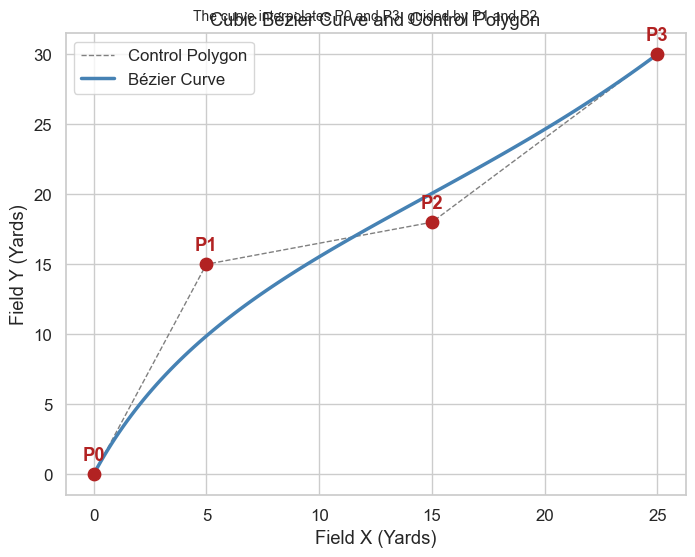

In [6]:
# Define control points for a cubic curve (e.g., a receiver's corner route)
control_pts = pd.DataFrame({
    'x': [0, 5, 15, 25],
    'y': [0, 15, 18, 30],
    'point_id': [f'P{i}' for i in range(4)]
})

# Generate curve evaluation points
curve_df = eval_bezier(control_pts[['x', 'y']].values)

# Plot the curve along with its control polygon
plt.figure(figsize=(8, 6))
plt.plot(control_pts['x'], control_pts['y'], color='gray', linestyle='--', linewidth=1, label='Control Polygon')
plt.scatter(control_pts['x'], control_pts['y'], color='firebrick', s=80, zorder=5)

for _, row in control_pts.iterrows():
    plt.annotate(row['point_id'], (row['x'], row['y']), textcoords="offset points", 
                 xytext=(0, 10), ha='center', fontweight='bold', color='firebrick')

plt.plot(curve_df['x'], curve_df['y'], color='steelblue', linewidth=2.5, label='Bézier Curve')
plt.title('Cubic Bézier Curve and Control Polygon')
plt.suptitle('The curve interpolates P0 and P3, guided by P1 and P2', fontsize=10, y=0.92)
plt.xlabel('Field X (Yards)')
plt.ylabel('Field Y (Yards)')
plt.legend()
plt.show()

Changing the control points. Below we change the values of P2 to get a different curve.

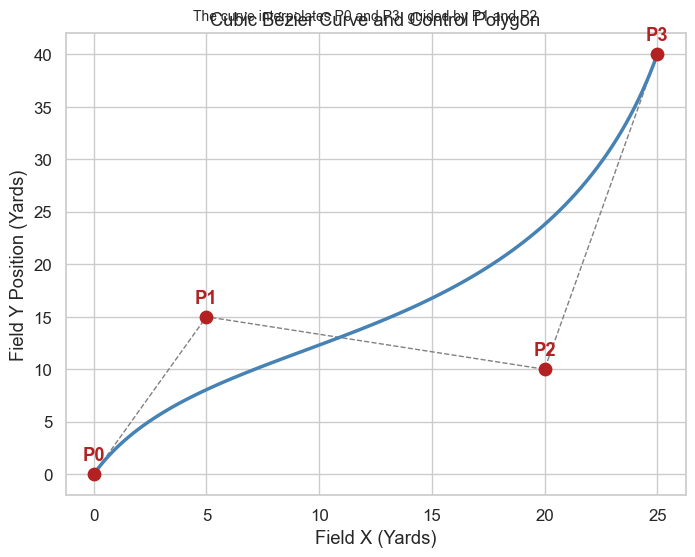

In [7]:
# Define control points for a cubic curve
control_pts = pd.DataFrame({
    'x': [0, 5, 20, 25],
    'y': [0, 15, 10, 40],
    'point_id': [f'P{i}' for i in range(4)]
})

# Generate curve evaluation points
curve_df = eval_bezier(control_pts[['x', 'y']].values)

# Plot
plt.figure(figsize=(8, 6))
plt.plot(control_pts['x'], control_pts['y'], color='gray', linestyle='--', linewidth=1)
plt.scatter(control_pts['x'], control_pts['y'], color='firebrick', s=80, zorder=5)

for _, row in control_pts.iterrows():
    plt.annotate(row['point_id'], (row['x'], row['y']), textcoords="offset points", 
                 xytext=(0, 10), ha='center', fontweight='bold', color='firebrick')

plt.plot(curve_df['x'], curve_df['y'], color='steelblue', linewidth=2.5)
plt.title('Cubic Bézier Curve and Control Polygon')
plt.suptitle('The curve interpolates P0 and P3, guided by P1 and P2', fontsize=10, y=0.92)
plt.xlabel('Field X (Yards)')
plt.ylabel('Field Y Position (Yards)')
plt.show()

Changing the control points. Below we change the values of P3 to get a different curve.

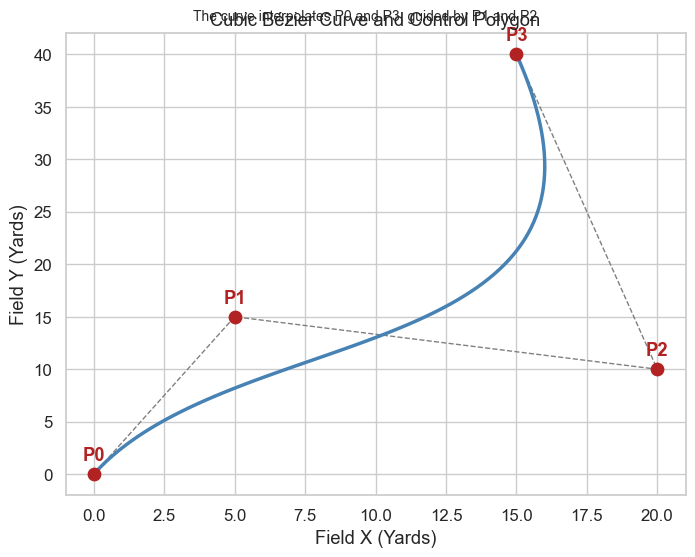

In [8]:
# Define control points for a cubic curve
control_pts = pd.DataFrame({
    'x': [0, 5, 20, 15],
    'y': [0, 15, 10, 40],
    'point_id': [f'P{i}' for i in range(4)]
})

# Generate curve evaluation points
curve_df = eval_bezier(control_pts[['x', 'y']].values)

# Plot
plt.figure(figsize=(8, 6))
plt.plot(control_pts['x'], control_pts['y'], color='gray', linestyle='--', linewidth=1)
plt.scatter(control_pts['x'], control_pts['y'], color='firebrick', s=80, zorder=5)

for _, row in control_pts.iterrows():
    plt.annotate(row['point_id'], (row['x'], row['y']), textcoords="offset points", 
                 xytext=(0, 10), ha='center', fontweight='bold', color='firebrick')

plt.plot(curve_df['x'], curve_df['y'], color='steelblue', linewidth=2.5)
plt.title('Cubic Bézier Curve and Control Polygon')
plt.suptitle('The curve interpolates P0 and P3, guided by P1 and P2', fontsize=10, y=0.92)
plt.xlabel('Field X (Yards)')
plt.ylabel('Field Y (Yards)')
plt.show()

### Task
Change the values of the points to make an S shape that goes close to the point (10,10).

### Task
Increase all of the value for x and y in the Points by 20. How does the curve change?

We will parameterize the time steps $t_i \in [0, 1]$ based on tracking frames, and fit control points using **Nonlinear Least Squares (NLS)** or numerical optimization (`scipy.optimize.minimize`).

### Parameterizing Time and Objective Function

To fit a parametric curve $(x(t), y(t))$ to observed data points $(x_k, y_k)_{k=1}^K$, we normalize time frames to $t_k = \frac{k-1}{K-1} \in [0, 1]$.

We then define the sum of squared Euclidean error (SSE):

$$\text{SSE}(P_0, P_1, P_2, P_3) = \sum_{k=1}^K \left[ \left( x_k - X_B(t_k) \right)^2 + \left( y_k - Y_B(t_k) \right)^2 \right]$$

Because $P_0 = (x_1, y_1)$ and $P_3 = (x_K, y_K)$ are fixed by the trajectory's start and end points, we only need to optimize over the intermediate control points $(P_1, P_2)$.

Below is code to estimate values for $P_0, P_1, P_2, P_3$:

In [9]:
def fit_cubic_bezier(obs_x, obs_y):
    obs_x = np.array(obs_x)
    obs_y = np.array(obs_y)
    K = len(obs_x)
    t_vec = np.linspace(0, 1, K)
    
    # Endpoints are interpolated directly
    P0 = np.array([obs_x[0], obs_y[0]])
    P3 = np.array([obs_x[-1], obs_y[-1]])
    
    # Initial guesses for intermediate control points P1 and P2 (1/3 and 2/3 along straight path)
    init_params = [
        P0[0] + (P3[0] - P0[0]) / 3, # P1_x
        P0[1] + (P3[1] - P0[1]) / 3, # P1_y
        P0[0] + 2 * (P3[0] - P0[0]) / 3, # P2_x
        P0[1] + 2 * (P3[1] - P0[1]) / 3  # P2_y
    ]
    
    # SSE loss function
    def loss_fn(params):
        ctrl_mat = np.array([
            P0,
            [params[0], params[1]],
            [params[2], params[3]],
            P3
        ])
        pred = eval_bezier(ctrl_mat, t_vec=t_vec)
        return np.sum((obs_x - pred['x'])**2 + (obs_y - pred['y'])**2)
    
    # Perform optimization using BFGS
    opt = minimize(loss_fn, init_params, method='BFGS')
    
    fitted_ctrl = np.array([
        P0,
        [opt.x[0], opt.x[1]],
        [opt.x[2], opt.x[3]],
        P3
    ])
    
    df_ctrl = pd.DataFrame(fitted_ctrl, columns=['x', 'y'])
    df_ctrl['point_id'] = [f'P{i}' for i in range(4)]
    
    return {
        'control_points': df_ctrl,
        'sse': opt.fun,
        'fitted_points': eval_bezier(fitted_ctrl, t_vec=np.linspace(0, 1, 100))
    }

### Visualizing A Fitted Route

In [10]:
route_data = df_single_play
route_data.head()

,game_id,play_id,nfl_id,time,x,y,s,a,dis,o,dir,event
0,2023123114,2735,56220,2024-01-01T03:23:40.500,91.24,31.88,0.00,0.00,0.00,75.31,13.04,ball_snap
1,2023123114,2735,56220,2024-01-01T03:23:40.600,91.25,31.89,0.00,0.00,0.00,75.31,33.63,NaN
2,2023123114,2735,56220,2024-01-01T03:23:40.700,91.25,31.89,0.02,0.43,0.00,75.31,58.98,NaN
3,2023123114,2735,56220,2024-01-01T03:23:40.800,91.26,31.89,0.10,0.85,0.01,75.31,60.23,NaN
4,2023123114,2735,56220,2024-01-01T03:23:40.900,91.27,31.90,0.24,1.15,0.02,75.31,68.11,NaN


Below we fit data to our route. In the image the dots are the actual and the line is the Bezier fit.

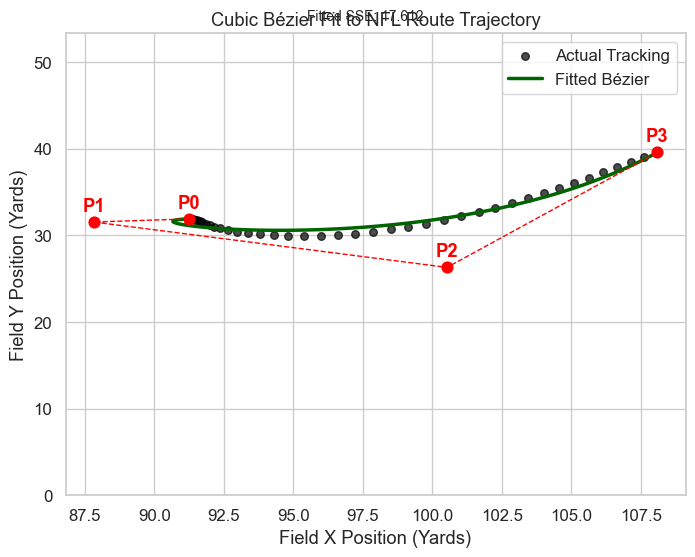

In [11]:
fit_results = fit_cubic_bezier(route_data['x'], route_data['y'])

ctrl_pts = fit_results['control_points']
fitted_pts = fit_results['fitted_points']

plt.figure(figsize=(8, 6))
# Raw noisy tracking points
plt.scatter(route_data['x'], route_data['y'], color='black', alpha=0.7, s=30, label='Actual Tracking')
# Fitted Bézier curve
plt.plot(fitted_pts['x'], fitted_pts['y'], color='darkgreen', linewidth=2.5, label='Fitted Bézier')
# Control points and polygon
plt.plot(ctrl_pts['x'], ctrl_pts['y'], color='red', linestyle='--', linewidth=1)
plt.scatter(ctrl_pts['x'], ctrl_pts['y'], color='red', s=60, zorder=5)

for _, row in ctrl_pts.iterrows():
    plt.annotate(row['point_id'], (row['x'], row['y']), textcoords="offset points", 
                 xytext=(0, 8), ha='center', color='red', fontweight='bold')

plt.ylim(0, 53.3)
plt.title('Cubic Bézier Fit to NFL Route Trajectory')
plt.suptitle(f"Fitted SSE: {fit_results['sse']:.3f}", fontsize=10, y=0.92)
plt.xlabel('Field X Position (Yards)')
plt.ylabel('Field Y Position (Yards)')
plt.legend()
plt.show()

### Dynamic Tracing with `matplotlib.animation`

In [12]:
# Prepare fine-grained evaluation grid for smooth animation
anim_fitted = fit_results['fitted_points'].copy()

fig, ax = plt.subplots(figsize=(8, 6))

def update(frame):
    ax.clear()
    # Sub-data up to current frame
    sub_fitted = anim_fitted.iloc[:frame+1]
    current_t = sub_fitted['t'].iloc[-1] if len(sub_fitted) > 0 else 0
    
    # Background control polygon
    ax.plot(ctrl_pts['x'], ctrl_pts['y'], color='gray', linestyle='--', alpha=0.7)
    ax.scatter(ctrl_pts['x'], ctrl_pts['y'], color='red', s=40)
    for _, row in ctrl_pts.iterrows():
        ax.annotate(row['point_id'], (row['x'], row['y']), textcoords="offset points", 
                    xytext=(0, 8), ha='center', color='red')
        
    # Background raw points
    ax.scatter(route_data['x'], route_data['y'], color='gray', alpha=0.4, s=20)
    
    # Progressive Bézier path
    ax.plot(sub_fitted['x'], sub_fitted['y'], color='darkgreen', linewidth=2.5)
    
    # Active player position
    if len(sub_fitted) > 0:
        ax.scatter(sub_fitted['x'].iloc[-1], sub_fitted['y'].iloc[-1], color='navy', s=100, zorder=6)
        
    ax.set_ylim(0, 53.3)
    ax.set_title('NFL Player Route Tracing via Cubic Bézier Curve')
    ax.set_xlabel('Field X Position (Yards)')
    ax.set_ylabel('Field Y Position (Yards)')
    ax.text(0.02, 0.95, f'Parametric time step: t = {current_t:.2f}', transform=ax.transAxes, bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

anim = animation.FuncAnimation(fig, update, frames=len(anim_fitted), interval=100)
anim.save('play.gif', writer='pillow', fps=10)
plt.close()

# Display gif in notebook
HTML('<img src="play.gif">')

### Task
In the above animation, we see that $P_1$ is nearly directly to the left of $P_0$ and that in the estimated Bezier curve, the player appears to go backward. Why might that be?

In [13]:
# Get the distinct game_id, play_id, nfl_id combinations
routes = tracking[['game_id', 'play_id', 'nfl_id']].drop_duplicates().reset_index(drop=True)
n_routes = len(routes)

### Task
Find a couple of other plays by looking through the *routes* dataframe and animate them.

In [14]:
bezier_out = pd.DataFrame({
    'x0': [np.nan] * n_routes,
    'y0': [np.nan] * n_routes,
    'x1': [np.nan] * n_routes,
    'y1': [np.nan] * n_routes,
    'x2': [np.nan] * n_routes,
    'y2': [np.nan] * n_routes,
    'x3': [np.nan] * n_routes,
    'y3': [np.nan] * n_routes,
    'route_ran': [np.nan] * n_routes
})

Next we will take all the WR routes and get the Bezier curves for them.

*Note: The cell below performs the full loop across all routes and may take some time to run.*

In [ ]:
# Loop through all routes to extract fitted control points (disabled by default)
# for i in range(n_routes):
#     g, p, n = routes.loc[i, ['game_id', 'play_id', 'nfl_id']]
#     df_sub = tracking[(tracking['game_id'] == g) & (tracking['play_id'] == p) & (tracking['nfl_id'] == n)].copy()
#     p_info = player_play[(player_play['game_id'] == g) & (player_play['play_id'] == p) & (player_play['nfl_id'] == n)]
#     
#     if len(p_info) > 0:
#         if p_info['play_direction'].values[0] == 'left':
#             df_sub['x'] = 120 - df_sub['x']
#             df_sub['y'] = 53.3333 - df_sub['y']
#         
#         df_sub['x'] = df_sub['x'] - df_sub['x'].iloc[0]
#         df_sub['y'] = df_sub['y'] - df_sub['y'].iloc[0]
#         
#         snaps = df_sub.index[df_sub['event'].str.contains('snap', na=False)].tolist()
#         w_snap = snaps[0] if snaps else df_sub.index[0]
#         outcomes = df_sub.index[df_sub['event'].str.contains('outcome', na=False)].tolist()
#         w_out = outcomes[0] if outcomes else df_sub.index[-1]
#         
#         df_sub = df_sub.loc[w_snap:w_out]
#         
#         fit_res = fit_cubic_bezier(df_sub['x'], df_sub['y'])
#         ctrls = fit_res['control_points']
#         bezier_out.loc[i] = [
#             ctrls['x'].iloc[0], ctrls['y'].iloc[0],
#             ctrls['x'].iloc[1], ctrls['y'].iloc[1],
#             ctrls['x'].iloc[2], ctrls['y'].iloc[2],
#             ctrls['x'].iloc[3], ctrls['y'].iloc[3],
#             p_info['route_ran'].values[0]
#         ]

# bezier_out.to_csv('bezier_out.csv', index=False)

In [15]:
bezier_out = pd.read_csv("https://webpages.charlotte.edu/~mschuck1/sports/data/bezier_out.csv")
bezier_out = bezier_out.dropna(subset=['x0']).reset_index(drop=True)

Below we create a data frame for clustering the Bézier Points for each route.

In [16]:
feature_cols = ['x0', 'y0', 'x1', 'y1', 'x2', 'y2', 'x3', 'y3']
bezier_cluster = bezier_out[feature_cols].copy().astype(float)

scaler = StandardScaler()
scaled_features = scaler.fit_transform(bezier_cluster)

This is a way to find the number of clusters but not sure that I love it.

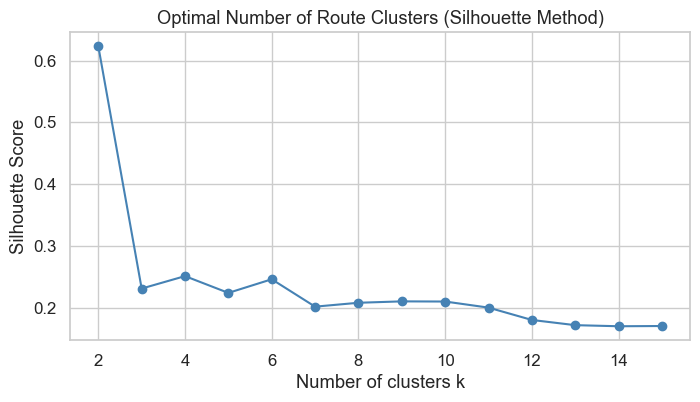

In [17]:
# Evaluate optimal k using Silhouette Method
sil_scores = []
k_range = range(2, 16)
for k in k_range:
    km = KMeans(n_clusters=k, n_init=25, random_state=42)
    labels = km.fit_predict(scaled_features)
    sil_scores.append(silhouette_score(scaled_features, labels))

plt.figure(figsize=(8, 4))
plt.plot(k_range, sil_scores, marker='o', color='steelblue')
plt.title('Optimal Number of Route Clusters (Silhouette Method)')
plt.xlabel('Number of clusters k')
plt.ylabel('Silhouette Score')
plt.show()

In [18]:
# Get a summary of the types of routes run in these data.
bezier_out['route_ran'].value_counts()

route_ran
GO        1672
HITCH     1368
CROSS      964
IN         827
OUT        812
POST       778
SLANT      609
CORNER     568
SCREEN     296
FLAT       182
WHEEL        9
ANGLE        2
Name: count, dtype: int64

It looks like there are about 10 types of routes so let's use 10 clusters.

In [19]:
k_chosen = 10
km_res = KMeans(n_clusters=k_chosen, n_init=25, random_state=42)
bezier_cluster['cluster'] = km_res.fit_predict(scaled_features) + 1  # 1-indexed to match R
bezier_cluster['route_ran'] = bezier_out['route_ran']

Below is a crosstabulation table for the routes and the clusters.

In [20]:
pd.crosstab(bezier_cluster['route_ran'], bezier_cluster['cluster'])

cluster,1,2,3,4,5,6,7,8,9,10
route_ran,,,,,,,,,,
ANGLE,0,0,1,0,0,0,0,0,0,1
CORNER,15,316,30,1,31,1,0,5,124,45
CROSS,10,77,344,14,267,56,15,43,41,97
FLAT,0,0,40,3,25,17,4,10,0,83
GO,14,720,124,0,58,55,0,34,348,319
HITCH,83,433,122,0,87,8,0,5,14,616
IN,37,317,108,0,118,10,0,11,18,208
OUT,33,170,192,0,141,8,0,16,5,247
POST,11,404,30,0,21,8,0,9,232,63


In [21]:
pd.DataFrame(km_res.cluster_centers_, columns=feature_cols)

,x0,y0,x1,y1,x2,y2,x3,y3
0,0.192285,-0.039112,3.704271,0.627017,0.679183,-0.655980,0.226367,-0.691971
1,0.113318,-0.019448,-0.540611,-0.028767,0.320273,-0.027166,0.392901,0.006219
2,0.141769,-0.029347,0.389222,0.463742,-0.256594,-1.090412,-0.352818,-1.249181
3,-8.091600,-4.009215,-1.485904,-3.289126,-1.604518,-2.606836,-1.424146,-2.207792
4,0.147554,-0.016627,0.852158,-0.676769,0.009571,1.311583,-0.217944,1.341683
5,-1.085196,4.208192,-0.332392,3.543692,-0.465191,2.235122,-0.277549,1.895997
6,-9.075698,3.449519,-1.411646,3.098260,-1.613903,2.462021,-1.501078,2.073211
7,-0.765293,-4.184128,-0.311400,-3.360677,-0.397385,-2.036430,-0.326061,-1.727946
8,0.142682,-0.006490,-0.023799,0.008923,1.780711,0.045461,2.000472,-0.000044
9,0.094506,-0.015264,-0.134922,-0.081555,-0.765245,0.090246,-0.776050,0.145571
